# Disciplyn: Live Model Demo (runs in about 2 minutes)
Raw trades → feature engineering → train models live → evaluate → overfitting check → predict on unseen traders.

The full training (algorithm comparison + tuning of all 14 models) is in `Disciplyn_Model_Training.ipynb`.

In [1]:
import time, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sklearn
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
from features import MODELS, trader_features          # our feature engineering module
import training_pipeline as tp                        # our training pipeline
print("scikit-learn", sklearn.__version__, "| models defined:", len(MODELS))

scikit-learn 1.9.1 | models defined: 14


## 1. Load the raw dataset (1.9M trades)

In [2]:
t0 = time.time()
trades = pd.read_csv("data/trades.csv")
quest  = pd.read_csv("data/questionnaire.csv")
labels = pd.read_csv("data/labels.csv")
print(f"{len(trades):,} trades | {trades.trader_id.nunique():,} traders | {trades.shape[1]} columns | loaded in {time.time()-t0:.0f}s")
trades.sample(5, random_state=1)

1,944,823 trades | 10,000 traders | 40 columns | loaded in 4s


,trader_id,trade_id,trade_date,entry_time,exit_time,symbol,side,qty,entry_price,exit_price,...,pre_entry_return_15m_pct,volume_zscore_entry,rsi_14_entry,macd_hist_entry,market_sentiment_entry,india_vix,market_move_during_hold_pct,volume_zscore_exit,post_exit_return_30m_pct,journal_note
1935360,TR09952,TR09952-0004,2026-07-01,2026-07-01T14:56,2026-07-01T15:20,LT,SHORT,276,3506.55,3569.49,...,-0.871,3.464,25.29,0.746,0.948,11.83,0.876,0.979,-0.109,0
1361125,TR07028,TR07028-0035,2026-07-12,2026-07-12T10:15,2026-07-12T10:45,ADANIENT,LONG,80,3106.55,3060.40,...,1.686,4.312,88.17,-0.136,0.301,13.02,0.317,0.603,0.379,1
783956,TR04069,TR04069-0055,2026-08-09,2026-08-09T11:07,2026-08-09T11:46,ICICIBANK,SHORT,27,1205.66,1202.55,...,-2.414,1.877,27.53,-0.104,0.851,12.92,-0.245,0.851,0.139,1
722032,TR03747,TR03747-0091,2026-08-28,2026-08-28T09:54,2026-08-28T11:44,BANKNIFTY_FUT,SHORT,5,50472.18,51582.41,...,0.453,0.678,60.58,-0.206,0.403,13.07,0.631,-0.788,-0.225,1
1216392,TR06294,TR06294-0208,2026-08-15,2026-08-15T11:19,2026-08-15T11:29,AXISBANK,LONG,36,1166.91,1166.80,...,-0.340,0.129,50.42,-0.378,-0.638,12.52,-1.344,2.228,0.919,0


## 2. Feature engineering on one trader (live)
`trader_features()` in `features.py` converts raw trades into behavioural features.

In [3]:
tid = "TR02697"
one = trades[trades.trader_id == tid]
f = trader_features(one, quest[quest.trader_id == tid])
show = ["trades_per_day","quick_reentry_after_loss_rate","size_after_loss_vs_win","chase_entry_rate",
        "sl_modified_rate","loss_hold_vs_win_hold","avg_leverage","off_plan_rate","journal_loss_rate","q_impulsivity"]
print(f"Trader {tid}: {len(one)} trades -> {len([k for k in f if not k.startswith('_')])} features")
pd.Series({k: round(f[k], 3) for k in show}, name="value").to_frame()

Trader TR02697: 422 trades -> 66 features


,value
trades_per_day,7.033
quick_reentry_after_loss_rate,0.945
size_after_loss_vs_win,1.697
chase_entry_rate,0.569
sl_modified_rate,0.180
loss_hold_vs_win_hold,1.161
avg_leverage,3.323
off_plan_rate,0.810
journal_loss_rate,0.241
q_impulsivity,4.500


## 3. Each of the 14 models uses its own features (20 tags → 14 models)

In [4]:
pd.DataFrame([{"model": k, "predicts": tp.target_of(v),
               "opposite tag (pair)": v.get("positive", "-"), "features": ", ".join(v["features"])}
              for k, v in MODELS.items()])

,model,predicts,opposite tag (pair),features
0,stop_loss,Ignoring Stop-Losses,Stop-Loss Adherence,"sl_set_rate, sl_modified_rate, sl_widened_rate..."
1,frequency,Overtrading,Controlled Trading Frequency,"trades_per_day, max_trades_per_day, median_gap..."
2,discipline,Lack of Discipline,Disciplined Trading,"sl_set_rate, target_set_rate, off_plan_rate, t..."
3,profit_exit,Greed,Profit Booking,"target_held_rate, giveback_ratio, win_hold_vs_..."
4,entry_timing,FOMO,Patience,"chase_entry_rate, avg_pre_entry_move, avg_entr..."
5,leverage,Overleveraging,Risk Management,"avg_leverage, max_leverage, p90_leverage, avg_..."
6,revenge,Revenge Trading,-,"gap_after_loss_vs_win, quick_reentry_after_los..."
7,panic,Panic Selling,-,"early_exit_rate, early_exit_in_selloff_rate, p..."
8,loss_aversion,Loss Aversion,-,"loss_hold_vs_win_hold, averaged_down_rate, avg..."
9,confirmation_bias,Confirmation Bias,-,"same_idea_reentry_rate, against_macd_rate, aga..."


## 4. Training data: 28,875 trader-month windows, split by trader (no leakage)

In [5]:
df = tp.load_dataset()
train, test = tp.split(df, test_size=0.2)
print(f"train: {len(train):,} windows from {train.trader_id.nunique():,} traders")
print(f"test : {len(test):,} windows from {test.trader_id.nunique():,} traders  (overlap: {len(set(train.trader_id)&set(test.trader_id))})")

train: 23,124 windows from 8,000 traders
test : 5,751 windows from 2,000 traders  (overlap: 0)


## 5. Train the Revenge Trading model live with 3 algorithms

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score

cfg = MODELS["revenge"]; X_cols, y_col = cfg["features"], "Revenge Trading"
Xtr, ytr, Xte, yte = train[X_cols], train[y_col], test[X_cols], test[y_col]
algos = {
  "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000)),
  "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=0)),
  "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0),
}
rows, fitted = [], {}
for name, model in algos.items():
    t0 = time.time(); model.fit(Xtr, ytr); fitted[name] = model
    p = model.predict_proba(Xte)[:, 1]; pred = (p >= 0.5).astype(int)
    rows.append({"algorithm": name, "accuracy": accuracy_score(yte, pred), "precision": precision_score(yte, pred),
                 "recall": recall_score(yte, pred), "f1": f1_score(yte, pred), "roc_auc": roc_auc_score(yte, p),
                 "train_roc_auc": roc_auc_score(ytr, model.predict_proba(Xtr)[:, 1]), "train_sec": round(time.time()-t0, 1)})
live = pd.DataFrame(rows).round(4); live["gap (overfit check)"] = (live.train_roc_auc - live.roc_auc).round(4)
live

,algorithm,accuracy,precision,recall,f1,roc_auc,train_roc_auc,train_sec,gap (overfit check)
0,Logistic Regression,0.8258,0.7903,0.8033,0.7968,0.9072,0.9083,0.1,0.0011
1,Random Forest,0.8355,0.8172,0.7898,0.8032,0.9184,0.9605,1.6,0.0421
2,Gradient Boosting,0.8378,0.8182,0.7951,0.8065,0.9206,0.9348,0.8,0.0142


## 6. Evaluation: confusion matrix, ROC curve and feature importance

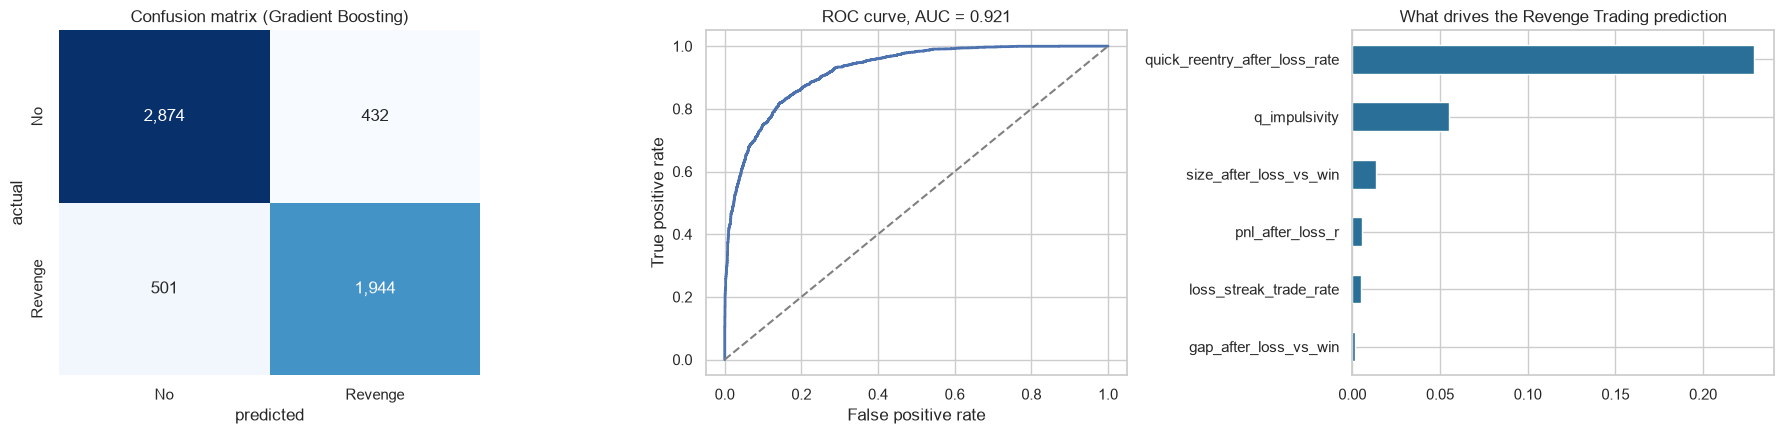

In [7]:
from sklearn.metrics import confusion_matrix, roc_curve
from sklearn.inspection import permutation_importance
best = live.sort_values("roc_auc").iloc[-1].algorithm; m = fitted[best]
p = m.predict_proba(Xte)[:, 1]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.heatmap(confusion_matrix(yte, p >= 0.5), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["No", "Revenge"], yticklabels=["No", "Revenge"])
ax[0].set_title(f"Confusion matrix ({best})"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("actual")
fpr, tpr, _ = roc_curve(yte, p); ax[1].plot(fpr, tpr, lw=2); ax[1].plot([0,1],[0,1],"--",c="grey")
ax[1].set_title(f"ROC curve, AUC = {roc_auc_score(yte, p):.3f}"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
imp = permutation_importance(m, Xte, yte, n_repeats=5, random_state=0, scoring="roc_auc")
pd.Series(imp.importances_mean, index=X_cols).sort_values().plot.barh(ax=ax[2], color="#2a6f97")
ax[2].set_title("What drives the Revenge Trading prediction"); plt.tight_layout()

## 7. Train all 14 models live (Gradient Boosting, no tuning) and check for overfitting

In [8]:
t0 = time.time(); rows = []
for name, cfg in MODELS.items():
    y = tp.target_of(cfg); f_ = cfg["features"]
    mdl = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(train[f_], train[y])
    pt = mdl.predict_proba(test[f_])[:, 1]; ptr = mdl.predict_proba(train[f_])[:, 1]
    rows.append({"model": name, "tag(s)": tp.display_name(cfg), "accuracy": accuracy_score(test[y], pt >= .5),
                 "f1": f1_score(test[y], pt >= .5), "test_auc": roc_auc_score(test[y], pt), "train_auc": roc_auc_score(train[y], ptr)})
all14 = pd.DataFrame(rows).round(4); all14["gap"] = (all14.train_auc - all14.test_auc).round(4)
all14["fit"] = np.where(all14.gap > 0.05, "overfitting", np.where(all14.train_auc < 0.75, "underfitting", "good fit"))
print(f"14 models trained in {time.time()-t0:.0f}s | avg accuracy {all14.accuracy.mean():.3f} | avg ROC-AUC {all14.test_auc.mean():.3f} | max gap {all14.gap.max():.3f}")
all14

14 models trained in 9s | avg accuracy 0.870 | avg ROC-AUC 0.942 | max gap 0.030


,model,tag(s),accuracy,f1,test_auc,train_auc,gap,fit
0,stop_loss,Ignoring Stop-Losses / Stop-Loss Adherence,0.8837,0.8485,0.9527,0.9611,0.0084,good fit
1,frequency,Overtrading / Controlled Trading Frequency,0.9320,0.9225,0.9848,0.9890,0.0042,good fit
2,discipline,Lack of Discipline / Disciplined Trading,0.9282,0.9120,0.9830,0.9898,0.0068,good fit
3,profit_exit,Greed / Profit Booking,0.8764,0.8584,0.9507,0.9641,0.0134,good fit
4,entry_timing,FOMO / Patience,0.9023,0.8884,0.9695,0.9760,0.0065,good fit
5,leverage,Overleveraging / Risk Management,0.8371,0.7907,0.9142,0.9243,0.0101,good fit
6,revenge,Revenge Trading,0.8378,0.8065,0.9206,0.9348,0.0142,good fit
7,panic,Panic Selling,0.8381,0.7920,0.9112,0.9253,0.0141,good fit
8,loss_aversion,Loss Aversion,0.8364,0.7910,0.9130,0.9298,0.0168,good fit
9,confirmation_bias,Confirmation Bias,0.8859,0.8638,0.9589,0.9720,0.0131,good fit


## 8. Final tuned models (saved by the full pipeline)
Each tag uses the best of 4 algorithms, chosen by 5-fold GroupKFold CV, then tuned with RandomizedSearchCV and given its own decision threshold.

In [9]:
m = json.load(open("models/metrics.json"))
final = pd.DataFrame([{"tag(s)": v["tag(s)"], "algorithm": v["algorithm"], "threshold": v["threshold"], **v["test"],
                       "train_auc": v.get("train_roc_auc"), "fit": v.get("fit_status")} for v in m.values()])
print("AVERAGE:", final[["accuracy","precision","recall","f1","roc_auc"]].mean().round(4).to_dict())
final

AVERAGE: {'accuracy': 0.8655, 'precision': 0.8229, 'recall': 0.8941, 'f1': 0.8564, 'roc_auc': 0.9425}


,tag(s),algorithm,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,train_auc,fit
0,Ignoring Stop-Losses / Stop-Loss Adherence,HistGradientBoosting,0.49,0.8774,0.8184,0.8834,0.8496,0.9528,0.9297,0.0857,0.9557,good fit
1,Overtrading / Controlled Trading Frequency,HistGradientBoosting,0.49,0.9308,0.9104,0.9336,0.9218,0.9850,0.9811,0.0481,0.9855,good fit
2,Lack of Discipline / Disciplined Trading,MLP (Neural Net),0.47,0.9298,0.9053,0.9232,0.9142,0.9841,0.9784,0.0500,0.9847,good fit
3,Greed / Profit Booking,RandomForest,0.47,0.8729,0.8310,0.8891,0.8591,0.9513,0.9402,0.0888,0.9664,good fit
4,FOMO / Patience,LogisticRegression,0.44,0.9038,0.8779,0.9123,0.8948,0.9700,0.9662,0.0677,0.9681,good fit
5,Overleveraging / Risk Management,MLP (Neural Net),0.44,0.8348,0.7594,0.8374,0.7965,0.9156,0.8720,0.1134,0.9103,good fit
6,Revenge Trading,HistGradientBoosting,0.47,0.8322,0.7776,0.8479,0.8112,0.9205,0.8998,0.1143,0.9264,good fit
7,Panic Selling,MLP (Neural Net),0.40,0.8258,0.7390,0.8562,0.7933,0.9117,0.8754,0.1157,0.9121,good fit
8,Loss Aversion,MLP (Neural Net),0.36,0.8152,0.7168,0.8835,0.7914,0.9145,0.8821,0.1155,0.9154,good fit
9,Confirmation Bias,HistGradientBoosting,0.51,0.8872,0.8611,0.8728,0.8669,0.9595,0.9504,0.0802,0.9693,good fit


## 9. Predict on traders the models have never seen

In [10]:
from predict import analyze
truth = labels.set_index("trader_id")
for p in ["impulsive", "disciplined"]:
    tr = pd.read_csv(f"samples/persona_{p}_trades.csv"); q = pd.read_csv(f"samples/persona_{p}_questionnaire.csv")
    tid = tr.trader_id.iloc[0]; r = analyze(tr, q)
    present = sorted([x for x in r["tags"] if x["present"]], key=lambda x: -x["probability"])
    ok = sum(truth.loc[tid, x["tag"]] == 1 for x in present)
    print(f"\n{p.upper()} trader {tid}: {len(tr)} trades -> BEHAVIOUR SCORE {r['behaviour_score']}/100  ({ok}/{len(present)} tags correct)")
    for x in present:
        print(f"   {'[-]' if x['polarity']=='negative' else '[+]'} {x['tag']:30s} {x['probability']:.0%}   truth={int(truth.loc[tid, x['tag']])}")


IMPULSIVE trader TR02697: 139 trades -> BEHAVIOUR SCORE 7/100  (8/9 tags correct)
   [-] Lack of Discipline             100%   truth=1
   [-] FOMO                           100%   truth=1
   [-] Overtrading                    100%   truth=1
   [-] Loss Aversion                  100%   truth=1
   [-] Confirmation Bias              100%   truth=1
   [-] Ignoring Stop-Losses           99%   truth=1
   [-] Revenge Trading                99%   truth=1
   [-] Greed                          98%   truth=1
   [-] Overleveraging                 72%   truth=0

DISCIPLINED trader TR04140: 33 trades -> BEHAVIOUR SCORE 94/100  (10/10 tags correct)
   [+] Learning from Losses           100%   truth=1
   [+] Controlled Trading Frequency   100%   truth=1
   [+] Patience                       100%   truth=1
   [+] Consistent Position Sizing     100%   truth=1
   [+] Profit Booking                 100%   truth=1
   [+] Disciplined Trading            99%   truth=1
   [+] Stop-Loss Adherence            99